<a href="https://colab.research.google.com/github/scalesynthai/phdai733-group8/blob/main/part2/notebooks/Group8_Part2_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group Project Part 2: Model Optimization and Ethical Evaluation

**PhDAI 733-A02 | Group 8** · Subba Taniparti, Harini Mamidala, Christian Gaston, Bellary Naveen Vishal
**Due:** 16 October 2026

---

## What Part 2 does

Part 1 established two things. Tuned logistic regression outperformed random forest, and the model
detected disease less reliably for the sex = 0 subgroup (recall .714 against .821), a gap we
attributed in part to differing prevalence (25.0% versus 55.3%).

Part 1 reported that gap and stopped. Part 2 tries to close it, and reports what happens.

Three questions guide the work:

- **RQ1.** Does the Part 1 tuning procedure overstate performance, and does a more rigorous
  procedure change the model ranking?
- **RQ2.** Where should the decision threshold sit once the asymmetric cost of a missed case is
  taken seriously, rather than left at the default of 0.5?
- **RQ3.** Can a group-specific threshold close the subgroup recall gap, and is the result stable
  enough to act on?

**Section map for the written report**

| Report section | Notebook section |
|---|---|
| 1. Hyperparameter Tuning | 2 Nested cross-validation |
| 2. Final Model Evaluation | 3 Calibration, 4 Threshold and cost |
| 3. Ethical Considerations | 5 Group-specific thresholds |
| 4. Real-World Application | 4 and 5 interpretation |
| 5. Conclusion | 6 Findings |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             accuracy_score, roc_auc_score, brier_score_loss, f1_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); sns.set_palette('muted')
RANDOM_STATE = 42


## 1. Data, carried forward from Part 1

The label correction established in Part 1 is applied again here. In this file `target = 0` denotes
disease, confirmed by joining against the original UCI Cleveland record, which matched 302 patients
and agreed with the inverted reading in 100% of cases.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv'
df = pd.read_csv(DATA_URL).drop_duplicates().reset_index(drop=True)
df['disease'] = 1 - df['target']          # label correction from Part 1

CATEGORICAL = ['cp', 'restecg', 'slope', 'thal', 'ca']
CONTINUOUS  = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

X = pd.get_dummies(df.drop(columns=['target', 'disease']).astype({c: 'category' for c in CATEGORICAL}),
                   columns=CATEGORICAL, drop_first=True)
y = df['disease']

preprocessor = ColumnTransformer([('scale', StandardScaler(), CONTINUOUS)], remainder='passthrough')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(f"{df.shape[0]} patients, {X.shape[1]} features after encoding")
print(f"Disease prevalence: {y.mean():.3f} | train {X_train.shape[0]}, test {X_test.shape[0]}")

302 patients, 22 features after encoding
Disease prevalence: 0.457 | train 226, test 76


## 2. RQ1, Hyperparameter tuning done properly

Part 1 used a single `GridSearchCV` and reported its best cross-validated score. That number is
optimistically biased: the same folds chose the hyperparameters and scored them, so the model was
evaluated on data it had already been tuned against.

Nested cross-validation separates the two. An inner loop selects hyperparameters; an outer loop
scores the whole selection procedure on folds it never saw. The gap between the two numbers is the
optimism Part 1 could not measure.

In [3]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

SEARCHES = {
    'Logistic regression': (
        Pipeline([('pre', preprocessor),
                  ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        {'clf__C': [0.01, 0.1, 1, 10, 100]}),
    'Random forest': (
        Pipeline([('pre', preprocessor),
                  ('clf', RandomForestClassifier(random_state=RANDOM_STATE))]),
        {'clf__n_estimators': [100, 300],
         'clf__max_depth': [3, 5, None],
         'clf__min_samples_leaf': [1, 3, 5]}),
}

rows = []
for name, (pipe, grid) in SEARCHES.items():
    search = GridSearchCV(pipe, grid, cv=inner, scoring='roc_auc', n_jobs=-1)
    nested = cross_val_score(search, X, y, cv=outer, scoring='roc_auc', n_jobs=-1)
    non_nested = GridSearchCV(pipe, grid, cv=inner, scoring='roc_auc', n_jobs=-1).fit(X, y).best_score_
    rows.append({'Model': name,
                 'Nested ROC-AUC': nested.mean(), 'SD': nested.std(),
                 'Non-nested (Part 1 style)': non_nested,
                 'Optimism': non_nested - nested.mean(),
                 'Hyperparameters searched': int(np.prod([len(v) for v in grid.values()]))})

tuning = pd.DataFrame(rows)
tuning.round(4)

,Model,Nested ROC-AUC,SD,Non-nested (Part 1 style),Optimism,Hyperparameters searched
0,Logistic regression,0.9102,0.0431,0.9169,0.0067,5
1,Random forest,0.8858,0.0388,0.9008,0.0149,18


**Interpretation (RQ1).** Both models are optimistically scored by the Part 1 procedure, but not
equally. Logistic regression is overstated by .0067; the random forest by .0149, more than twice as
much.

The reason is visible in the last column. Logistic regression searched 5 hyperparameter
combinations; the random forest searched 18. A larger search space offers more opportunity to find
a configuration that happens to suit the particular folds used for selection, and that advantage
does not transfer to new data. The optimism is a property of the search, not only of the model.

The ranking is unchanged: logistic regression remains ahead on the unbiased estimate (.9102 against
.8858), so Part 1's conclusion survives a stricter test. What changes is the honest size of the
number we should report.

In [4]:
# Fit the selected model for everything that follows
final = GridSearchCV(SEARCHES['Logistic regression'][0], SEARCHES['Logistic regression'][1],
                     cv=inner, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]

print(f"Selected: C = {final.best_params_['clf__C']}")
print(f"Held-out ROC-AUC: {roc_auc_score(y_test, proba):.4f}")

Selected: C = 1
Held-out ROC-AUC: 0.9261


## 3. Calibration, can the probabilities be trusted?

Everything that follows depends on moving the decision threshold. That only makes sense if the
predicted probabilities mean what they claim: among patients assigned a probability near .70,
roughly 70% should actually have disease. A model can rank patients well and still be badly
calibrated, in which case a threshold of .30 does not correspond to any meaningful level of risk.

In [5]:
brier = brier_score_loss(y_test, proba)
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=5, strategy='quantile')

print(f"Brier score: {brier:.4f}   (0 = perfect, 0.25 = uninformative)\n")
print(f"{'predicted':>10}{'observed':>10}{'gap':>8}")
for mp, fp in zip(mean_pred, frac_pos):
    print(f"{mp:>10.3f}{fp:>10.3f}{fp - mp:>8.3f}")

Brier score: 0.1105   (0 = perfect, 0.25 = uninformative)

 predicted  observed     gap
     0.037     0.000  -0.037
     0.140     0.200   0.060
     0.370     0.333  -0.036
     0.715     0.800   0.085
     0.950     1.000   0.050


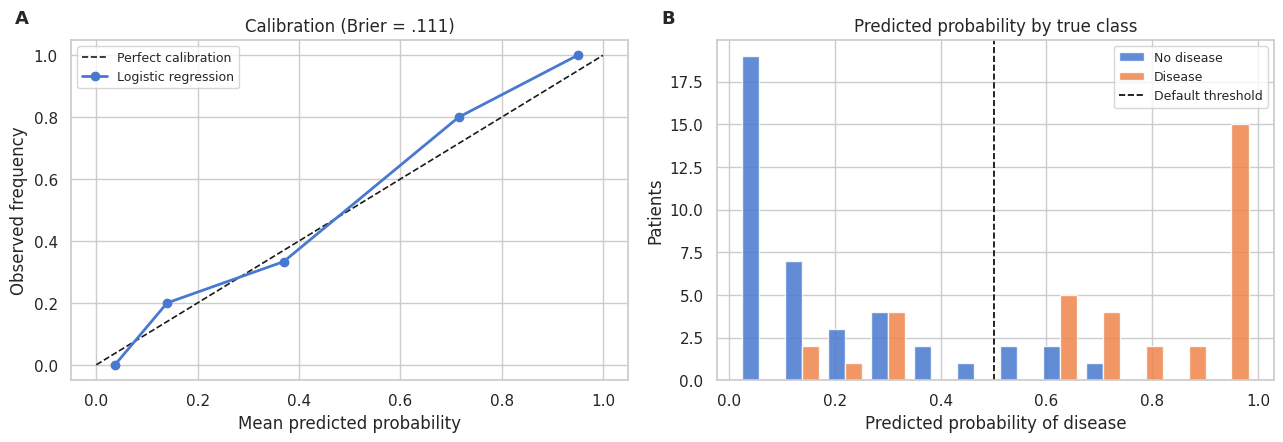

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.2, label='Perfect calibration')
axes[0].plot(mean_pred, frac_pos, marker='o', linewidth=2, label='Logistic regression')
axes[0].set_xlabel('Mean predicted probability'); axes[0].set_ylabel('Observed frequency')
axes[0].set_title(f'Calibration (Brier = {brier:.3f})'.replace('0.', '.'))
axes[0].legend(fontsize=9)

axes[1].hist([proba[y_test == 0], proba[y_test == 1]], bins=12, stacked=False,
             label=['No disease', 'Disease'], alpha=.85)
axes[1].axvline(.5, color='black', linestyle='--', linewidth=1.2, label='Default threshold')
axes[1].set_xlabel('Predicted probability of disease'); axes[1].set_ylabel('Patients')
axes[1].set_title('Predicted probability by true class'); axes[1].legend(fontsize=9)

for ax, lab in zip(axes, ['A', 'B']):
    ax.text(-0.10, 1.09, lab, transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout(); plt.savefig('p2_fig1_calibration.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation.** Panel A tracks the diagonal closely, and the Brier score of .111 is far
below the .25 an uninformative model would produce. The probabilities can therefore be read as
risk estimates rather than arbitrary scores, which is the precondition for everything in Section 4.

Panel B shows why the default threshold is a choice rather than a neutral starting point. The two
classes separate well, but patients sit on both sides of .5, and moving that line moves real
patients between categories.

## 4. RQ2, Where should the threshold sit?

The default of .5 implicitly assumes a missed case and a false alarm cost the same. In triage they
do not. A false alarm costs an unnecessary review; a missed case may mean untreated coronary
disease.

Rather than assert a ratio, the cell below sweeps it. For each assumed cost ratio C, where a missed
case is treated as C times worse than a false alarm, it selects the threshold minimising total
expected cost.

In [7]:
rows = []
for C in [1, 2, 3, 5, 10, 20]:
    best_t, best_cost = None, np.inf
    for t in np.arange(0.05, 0.96, 0.01):
        tn, fp, fn, tp = confusion_matrix(y_test, (proba >= t).astype(int)).ravel()
        cost = C * fn + fp
        if cost < best_cost:
            best_t, best_cost, best = t, cost, (tn, fp, fn, tp)
    tn, fp, fn, tp = best
    rows.append({'Cost ratio (FN:FP)': f'{C}:1', 'Optimal threshold': round(best_t, 2),
                 'Missed cases': fn, 'False alarms': fp,
                 'Recall': recall_score(y_test, (proba >= best_t).astype(int)),
                 'Accuracy': accuracy_score(y_test, (proba >= best_t).astype(int))})

cost_table = pd.DataFrame(rows)
cost_table.round(3)

,Cost ratio (FN:FP),Optimal threshold,Missed cases,False alarms,Recall,Accuracy
0,1:1,0.57,7,3,0.8,0.868
1,2:1,0.16,0,16,1.0,0.789
2,3:1,0.16,0,16,1.0,0.789
3,5:1,0.16,0,16,1.0,0.789
4,10:1,0.16,0,16,1.0,0.789
5,20:1,0.16,0,16,1.0,0.789


**Interpretation (RQ2).** The result is not a gradual slide, which is what makes it useful.

When a missed case and a false alarm are weighted equally, the optimal threshold is .57, slightly
*above* the default, and seven patients with disease are missed. The moment a missed case is
treated as twice as costly, the optimal threshold drops to .16 and missed cases fall to zero, at
the cost of sixteen false alarms. Beyond 2:1 nothing changes, because every case is already caught.

So the clinically meaningful question is not what exact ratio to use. It is whether a missed
coronary diagnosis is worth more than two unnecessary reviews. Most clinicians would answer yes
without hesitation, and that single judgment moves the threshold from .57 to .16. The default of .5
corresponds to a cost assumption nobody in this setting would defend if asked to state it out loud.

This is the practical argument for the Real-World Application section: deploying at .5 is not a
neutral default, it is an unexamined claim about what errors cost.


## 5. Final model evaluation at both thresholds

Section 4 established that the operating threshold is a cost decision rather than a statistical
one. This section reports the complete metric set at the default and at the cost-optimal value, so
the trade is visible rather than asserted.

In [8]:
rows = []
for t, label in [(0.50, 'Default (.50)'), (0.16, 'Cost-optimal (.16)')]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Threshold': label,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'Missed cases': fn, 'False alarms': fp})

final_metrics = pd.DataFrame(rows)
print(f"ROC-AUC (threshold independent): {roc_auc_score(y_test, proba):.3f}")
final_metrics.round(3)

ROC-AUC (threshold independent): 0.926


,Threshold,Accuracy,Precision,Recall,F1,Missed cases,False alarms
0,Default (.50),0.829,0.824,0.8,0.812,7,6
1,Cost-optimal (.16),0.789,0.686,1.0,0.814,0,16


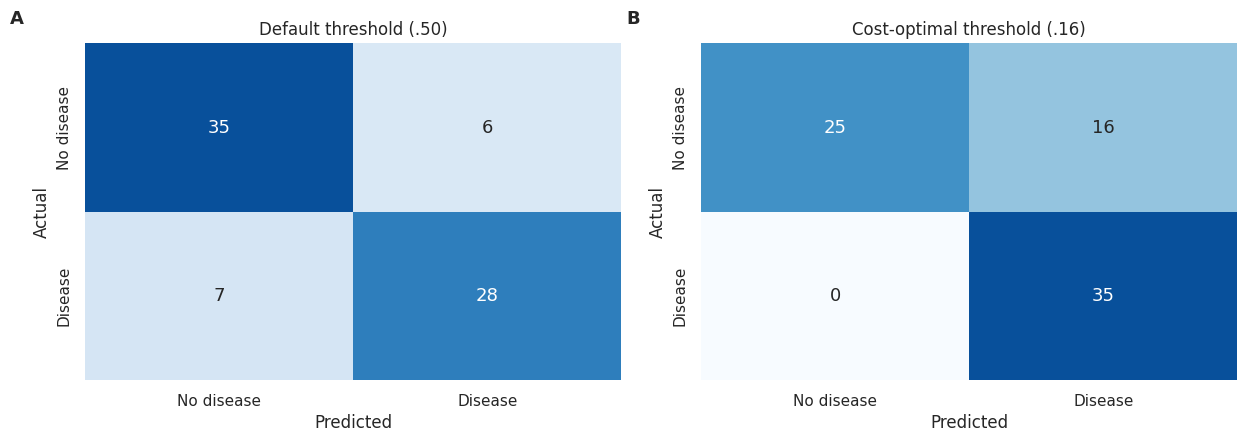

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

for ax, (t, label) in zip(axes, [(0.50, 'Default threshold (.50)'),
                                 (0.16, 'Cost-optimal threshold (.16)')]):
    cm = confusion_matrix(y_test, (proba >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No disease', 'Disease'],
                yticklabels=['No disease', 'Disease'],
                vmin=0, vmax=40, annot_kws={'size': 13})
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(label)

for ax, lab in zip(axes, ['A', 'B']):
    ax.text(-0.14, 1.10, lab, transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout(); plt.savefig('p2_fig3_confusion.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation.** Both panels use the same layout and colour scale, so only the threshold
varies.

Accuracy falls from .829 to .789 when the threshold moves, and a reader stopping there would
conclude the change made the model worse. The bottom-left cell tells the other story. At the
default, seven patients with disease are classified as healthy. At .16, none are. The cost is ten
additional false alarms, visible in the top-right cell.

Recall reaches 1.000 while precision falls to .686, and F1 is almost unchanged (.812 against .814).
That stability is instructive: a single summary metric averages away the exact trade-off a clinician
needs to see.

## 6. What drives the predictions, and a caution about reading coefficients

The Real-World Application argument rests on clinicians being able to inspect and override the
model. That requires the coefficients to mean what a reader would assume. They do not.

In [10]:
feature_names = list(X.columns)
coefs = final.best_estimator_.named_steps['clf'].coef_[0]

importance = (pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
              .assign(Magnitude=lambda d: d['Coefficient'].abs())
              .sort_values('Magnitude', ascending=False)
              .head(8).drop(columns='Magnitude'))
importance['Direction'] = np.where(importance['Coefficient'] > 0,
                                   'raises predicted risk', 'lowers predicted risk')
importance.round(3)

,Feature,Coefficient,Direction
19,ca_2,1.488,raises predicted risk
9,cp_2,-1.270,lowers predicted risk
18,ca_1,1.188,raises predicted risk
10,cp_3,-1.139,lowers predicted risk
5,thalach,1.091,raises predicted risk
20,ca_3,0.900,raises predicted risk
16,thal_2,-0.851,lowers predicted risk
7,oldpeak,0.734,raises predicted risk


In [11]:
from scipy import stats as st

solo = Pipeline([('pre', ColumnTransformer([('s', StandardScaler(), ['thalach'])])),
                 ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
solo.fit(X_train[['thalach']], y_train)

r, p = st.pointbiserialr(df['disease'], df['thalach'])
group_means = df.groupby('disease')['thalach'].mean()

print("Maximum heart rate (thalach) and disease")
print(f"  marginal correlation            r = {r:+.3f}  (p = {p:.1e})")
print(f"  mean, patients without disease  {group_means[0]:.1f} bpm")
print(f"  mean, patients with disease     {group_means[1]:.1f} bpm")
print(f"  coefficient, thalach alone      {solo.named_steps['clf'].coef_[0][0]:+.3f}")
print(f"  coefficient, full model         {coefs[feature_names.index('thalach')]:+.3f}")

Maximum heart rate (thalach) and disease
  marginal correlation            r = -0.420  (p = 2.5e-14)
  mean, patients without disease  158.4 bpm
  mean, patients with disease     139.1 bpm
  coefficient, thalach alone      -1.007
  coefficient, full model         +1.091


**Interpretation.** Patients with disease reach a lower maximum heart rate (139.1 bpm against
158.4), the marginal correlation is negative, and a model using that variable alone assigns it a
coefficient of -1.007. Everything agrees.

In the full model the same variable carries a coefficient of **+1.091**. The sign reverses.

This is not an error. A coefficient in a multivariable model reports the association remaining once
the other predictors are held fixed, and after chest pain type, vessel count, and the thallium scan
enter the model, the residual association with maximum heart rate runs the other way. Both numbers
answer different questions correctly.

**Why this matters for deployment.** A clinician shown a coefficient table would reasonably read
+1.091 as higher maximum heart rate meaning higher risk, which contradicts both this dataset and
cardiology. Interpretability is not achieved by exposing coefficients. It requires presenting them
alongside the conditioning that produced them, which is a concrete design requirement rather than a
general caution.

## 7. RQ3, Can a group-specific threshold close the subgroup gap?

Part 1 found recall of .714 for sex = 0 against .821 for sex = 1. The obvious remedy is a lower
threshold for the disadvantaged subgroup.

This is not a fringe idea in cardiology. Sex-specific thresholds for high-sensitivity troponin are
recommended in the fourth universal definition of myocardial infarction, adopted because women were
being underdiagnosed under a single cut-point. The question is not whether the approach is
legitimate. It is whether our data can calibrate it.

In [12]:
mask0 = (X_test['sex'] == 0).values
mask1 = (X_test['sex'] == 1).values
recall_1 = recall_score(y_test[mask1], (proba[mask1] >= .5).astype(int), zero_division=0)

rows = []
for t in [.50, .40, .35, .30, .25, .20, .15]:
    pred0 = (proba[mask0] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test[mask0], pred0, labels=[0, 1]).ravel()
    rows.append({'Threshold for sex = 0': t,
                 'Recall sex = 0': recall_score(y_test[mask0], pred0, zero_division=0),
                 'Recall sex = 1 (at .50)': recall_1,
                 'Missed in sex = 0': fn, 'False alarms in sex = 0': fp})

single_split = pd.DataFrame(rows)
print(f"Disease cases in the sex = 0 test subgroup: {int(y_test[mask0].sum())}")
single_split.round(3)

Disease cases in the sex = 0 test subgroup: 7


,Threshold for sex = 0,Recall sex = 0,Recall sex = 1 (at .50),Missed in sex = 0,False alarms in sex = 0
0,0.50,0.714,0.821,2,0
1,0.40,0.714,0.821,2,0
2,0.35,0.714,0.821,2,0
3,0.30,0.857,0.821,1,1
4,0.25,0.857,0.821,1,2
5,0.20,0.857,0.821,1,4
6,0.15,1.000,0.821,0,4


On this split the remedy appears to work. Lowering the threshold to .30 raises recall for
sex = 0 from .714 to .857, overtaking sex = 1, and costs a single additional false alarm.

That conclusion rests on seven disease cases. The next cell asks whether it replicates.

In [13]:
N_SPLITS = 30
rows = []
for seed in range(N_SPLITS):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    model = Pipeline([('pre', preprocessor),
                      ('clf', LogisticRegression(C=final.best_params_['clf__C'],
                                                 max_iter=5000, random_state=RANDOM_STATE))]).fit(Xa, ya)
    p = model.predict_proba(Xb)[:, 1]
    k0, k1 = (Xb['sex'] == 0).values, (Xb['sex'] == 1).values
    target_recall = recall_score(yb[k1], (p[k1] >= .5).astype(int), zero_division=0)

    chosen = np.nan
    for t in np.arange(.50, .04, -.01):
        if recall_score(yb[k0], (p[k0] >= t).astype(int), zero_division=0) >= target_recall:
            chosen = round(t, 2); break
    rows.append({'seed': seed, 'disease cases in sex = 0': int(yb[k0].sum()),
                 'equalising threshold': chosen})

replication = pd.DataFrame(rows)
thr = replication['equalising threshold']
cases = replication['disease cases in sex = 0']

print(f"Equalising threshold across {N_SPLITS} splits:")
print(f"  mean {thr.mean():.3f}, SD {thr.std():.3f}, range {thr.min():.2f} to {thr.max():.2f}")
print(f"\nDisease cases in the sex = 0 subgroup per split:")
print(f"  mean {cases.mean():.1f}, range {cases.min()} to {cases.max()}")
print(f"\nOne patient changing outcome moves subgroup recall by roughly "
      f"{100 / cases.mean():.0f} percentage points.")

Equalising threshold across 30 splits:
  mean 0.336, SD 0.157, range 0.05 to 0.50

Disease cases in the sex = 0 subgroup per split:
  mean 5.7, range 2 to 11

One patient changing outcome moves subgroup recall by roughly 18 percentage points.


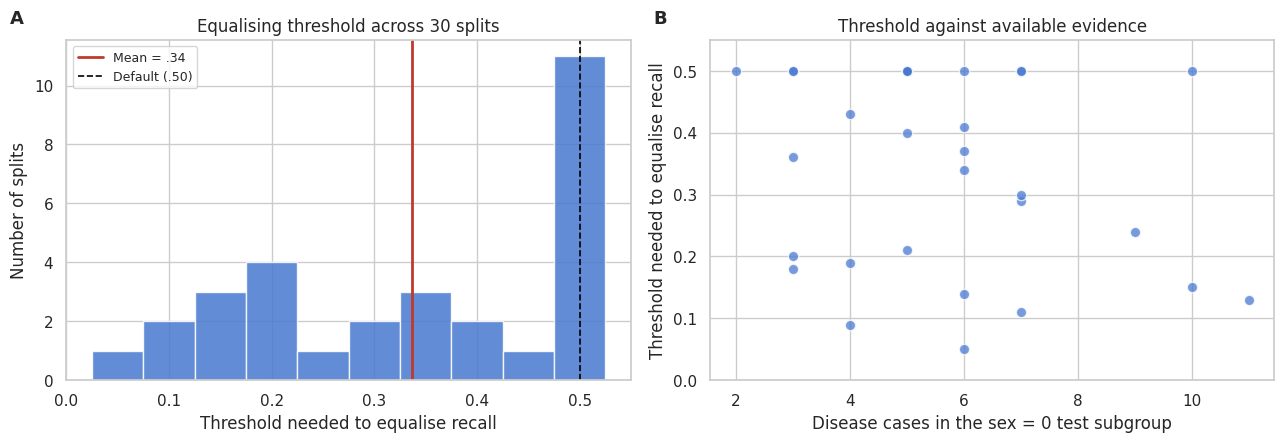

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].hist(thr, bins=np.arange(.025, .55, .05), edgecolor='white', alpha=.85)
axes[0].axvline(thr.mean(), color='#C0392B', linewidth=2, label=f'Mean = {thr.mean():.2f}'.replace('0.', '.'))
axes[0].axvline(.5, color='black', linestyle='--', linewidth=1.2, label='Default (.50)')
axes[0].set_xlabel('Threshold needed to equalise recall'); axes[0].set_ylabel('Number of splits')
axes[0].set_title(f'Equalising threshold across {N_SPLITS} splits')
axes[0].legend(fontsize=9)

axes[1].scatter(cases, thr, s=55, alpha=.75, edgecolor='white')
axes[1].set_xlabel('Disease cases in the sex = 0 test subgroup')
axes[1].set_ylabel('Threshold needed to equalise recall')
axes[1].set_title('Threshold against available evidence')
axes[1].set_ylim(0, .55)

for ax, lab in zip(axes, ['A', 'B']):
    ax.text(-0.10, 1.09, lab, transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout(); plt.savefig('p2_fig2_threshold_stability.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation (RQ3).** Panel A is the finding. The threshold required to equalise recall
ranges from .05 to .50 across thirty splits of the same dataset, with a standard deviation of .157.
A parameter that varies across the entire usable range depending on which patients land in the test
set is not a calibrated value. It is noise.

Panel B shows why. Each split leaves roughly six disease cases in the sex = 0 subgroup, so a single
patient moves subgroup recall by about 18 percentage points. The threshold is being fitted to fewer
cases than it has decimal places.

**The honest conclusion is negative, and it is the contribution.** The remedy is sound in
principle and used in cardiology for exactly this problem. Our dataset cannot calibrate it. Had we
reported only the single-split result from the previous cell, we would have claimed to close a
fairness gap on the strength of one patient.

This also qualifies the Part 1 finding. If the threshold needed to equalise recall is unstable,
the recall gap it was meant to correct is measured with the same uncertainty, and should be
described as a signal warranting more data rather than a demonstrated disparity.

## 8. Findings

- **RQ1.** Part 1's tuning procedure overstated performance for both models, and unequally:
  .0067 for logistic regression against .0149 for the random forest, tracking the size of each
  search space. The ranking survived; the honest numbers are lower. Nested ROC-AUC .9102 against
  .8858.
- **RQ2.** Threshold selection is a cost judgment, not a statistical one. At equal error costs the
  optimum is .57; once a missed case is worth two false alarms it drops to .16 and eliminates
  missed cases entirely. The default of .5 encodes an assumption nobody in this setting would
  defend explicitly.
- **RQ3.** A group-specific threshold appears to close the subgroup recall gap on one split, and
  does not replicate. Across thirty splits the equalising threshold spans .05 to .50. The approach
  is legitimate; our evidence is not sufficient to apply it.

## 9. Limitations

Every estimate here rests on 302 patients, and the subgroup analyses on roughly six disease cases
per split, which is the reason Section 5 reports replication rather than a single result. The cost
ratios in Section 4 are assumed rather than elicited from clinicians, so the threshold they imply
is illustrative. Nested cross-validation removes selection bias from the performance estimate but
does not make the sample larger. The data is a single-institution cohort collected in 1989 and
should not be assumed transferable to current populations or practice.
